In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
# each point is length, width, type (0, 1)

data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

mystery_flower = [5, 1]

In [ ]:
data = [
    ["this is class of fovl", 0],
    ["this is class of ml", 1],
    ["this is class of cv", 1],
    ["this is class of os", 0],
    ["this is class of vl", 0],
    ["this is class of ovl", 1],
    ["this is class of pl", 1]
]
print(data)

[['this is class of fovl', 0], ['this is class of ml', 1], ['this is class of cv', 1], ['this is class of os', 0], ['this is class of vl', 0], ['this is class of ovl', 1], ['this is class of pl', 1]]


In [ ]:
# Tokenize the sentences into words
tokenized_data = []
for sentence, label in data:
    # Simple word tokenization by splitting on whitespace
    words = sentence.split()
    tokenized_data.append([words, label])

for words, label in tokenized_data:
    print(f"Words: {words} -> Label: {label}")

Words: ['this', 'is', 'class', 'of', 'fovl'] -> Label: 0
Words: ['this', 'is', 'class', 'of', 'ml'] -> Label: 1
Words: ['this', 'is', 'class', 'of', 'cv'] -> Label: 1
Words: ['this', 'is', 'class', 'of', 'os'] -> Label: 0
Words: ['this', 'is', 'class', 'of', 'vl'] -> Label: 0
Words: ['this', 'is', 'class', 'of', 'ovl'] -> Label: 1
Words: ['this', 'is', 'class', 'of', 'pl'] -> Label: 1


In [ ]:
# Build the vocabulary of unique words
vocabulary = {}
word_set = set()

for words, label in tokenized_data:
    for word in words:
        word_set.add(word)

# Map each unique word to a unique integer ID
vocabulary = {word: index for index, word in enumerate(sorted(word_set))}

print("Vocabulary size:", len(vocabulary))
print("Vocabulary:")
for word, index in vocabulary.items():
    print(f"'{word}': {index}")

Vocabulary size: 11
Vocabulary:
'class': 0
'cv': 1
'fovl': 2
'is': 3
'ml': 4
'of': 5
'os': 6
'ovl': 7
'pl': 8
'this': 9
'vl': 10


In [ ]:
# Vectorize the tokenized data
vectors = []
vocab_size = len(vocabulary)

for words, label in tokenized_data:
    # Initialize a zero vector for the sentence
    vector = [0] * vocab_size
    for word in words:
        if word in vocabulary:
            vector[vocabulary[word]] = 1
    vectors.append([vector, label])

# Display the resulting vectors
for vector, label in vectors:
    print(f"Vector: {vector} -> Label: {label}")

Vector: [1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0] -> Label: 0
Vector: [1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0] -> Label: 1
Vector: [1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0] -> Label: 1
Vector: [1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0] -> Label: 0
Vector: [1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1] -> Label: 0
Vector: [1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0] -> Label: 1
Vector: [1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0] -> Label: 1


In [ ]:
# Define a lookup representation (converting word tokens to their vocabulary index sequences)
lookup_vectors = []

for words, label in tokenized_data:
    # Map each word to its corresponding index in the vocabulary
    lookup_vector = [vocabulary[word] for word in words if word in vocabulary]
    lookup_vectors.append([lookup_vector, label])

# Display the resulting lookup index vectors
for lookup_vector, label in lookup_vectors:
    print(f"Sentence tokens: {lookup_vector} -> Label: {label}")

Sentence tokens: [9, 3, 0, 5, 2] -> Label: 0
Sentence tokens: [9, 3, 0, 5, 4] -> Label: 1
Sentence tokens: [9, 3, 0, 5, 1] -> Label: 1
Sentence tokens: [9, 3, 0, 5, 6] -> Label: 0
Sentence tokens: [9, 3, 0, 5, 10] -> Label: 0
Sentence tokens: [9, 3, 0, 5, 7] -> Label: 1
Sentence tokens: [9, 3, 0, 5, 8] -> Label: 1


In [ ]:
import numpy as np

# Prepare input matrix x and target labels y from the existing 'vectors' list
x = np.array([item[0] for item in vectors]) # shape: (7, 11)
y = np.array([item[1] for item in vectors]).reshape(-1, 1) # shape: (7, 1)

# Set random seed for reproducibility
np.random.seed(42)

# 1. Dimensions
vocab_size = x.shape[1] # 11
embedding_dim = 4      # Choose an embedding dimension (e.g., 4)

# 2. Weights and Biases Initialization
# Embedding Matrix E
E = np.random.randn(vocab_size, embedding_dim)

# Layer 1: 2 nodes
W1 = np.random.randn(embedding_dim, 2)
b1 = np.zeros((1, 2))

# Layer 2: 3 nodes
W2 = np.random.randn(2, 3)
b2 = np.zeros((1, 3))

# Output Layer: 1 node (since we have a binary classification task)
W_out = np.random.randn(3, 1)
b_out = np.zeros((1, 1))

# Forward Pass Function
def forward(x):
    # Embedding step: x * E
    embedded = np.dot(x, E)

    # Layer 1: Input to 2 nodes (using sigmoid activation)
    z1 = np.dot(embedded, W1) + b1
    a1 = sigmoid(z1)

    # Layer 2: 2 nodes to 3 nodes
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Output Layer: 3 nodes to 1 node
    z_out = np.dot(a2, W_out) + b_out
    output = sigmoid(z_out)

    return embedded, a1, a2, output

# Run a single forward pass demo
embedded, a1, a2, predictions = forward(x)
print("Predictions for the 7 sentences:")
print(predictions)
print("\nActual Labels:")
print(y)

Predictions for the 7 sentences:
[[0.59105317]
 [0.5846994 ]
 [0.60029026]
 [0.58829045]
 [0.5993091 ]
 [0.59628576]
 [0.60085831]]

Actual Labels:
[[0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]]


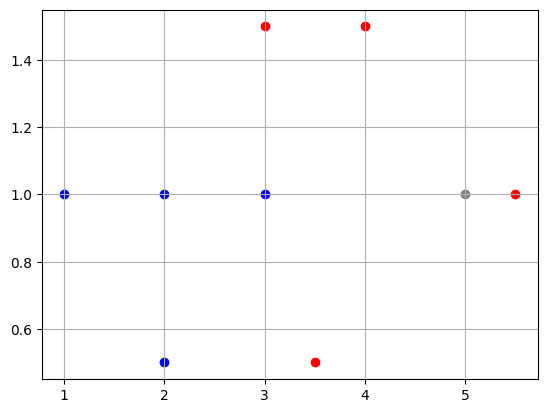

In [ ]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [ ]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [ ]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

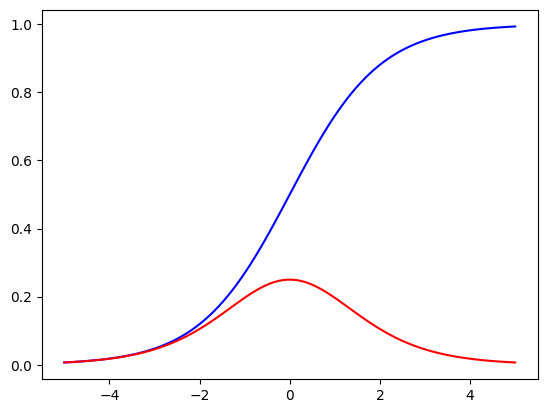

In [ ]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

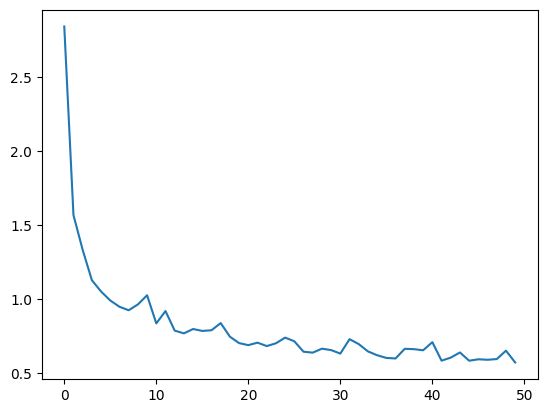

In [ ]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 5000
    learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

In [ ]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.9946743212759938
close to 0 -> blue, close to 1 -> red


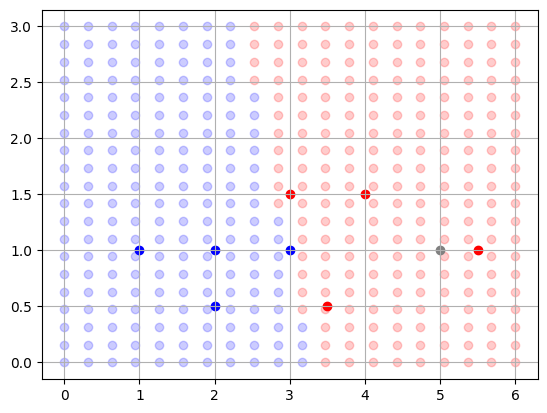

In [ ]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()